# Grafos dirigidos

**Matemática Discreta (2026/27)** · Edgar Martínez-Moro · Departamento de Matemática Aplicada, Escuela de Ingeniería Informática, Universidad de Valladolid

Este cuaderno acompaña a la sesión 17 del tema de **teoría de grafos**. Contiene:

1. Grados de entrada y salida, fuentes, pozos y grafo subyacente.
2. Matriz, trayectorias y aciclicidad.
3. El algoritmo de Warshall para el cierre transitivo, comparado con los métodos de la sesión 13.
4. Isomorfismo de dígrafos y dígrafos no etiquetados.
5. Dígrafos acíclicos: etiquetado naturalmente ordenado y niveles.

## Repaso

Un dígrafo tiene **arcos** $(x,y)$ con sentido. $ing(x)$ es el número de arcos que llegan a $x$ y $exg(x)$ el de los que salen; $x$ es **fuente** si $ing(x)=0$ y **pozo** si $exg(x)=0$. Una relación binaria en un conjunto es lo mismo que un dígrafo (sesión 10).

Un dígrafo es un par `(vertices, arcos)`.

Para dibujar los grafos usamos una función sencilla con `matplotlib`: las posiciones de los vértices se dan a mano.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch



def dibujar(pos, aristas, dirigido=False, pesos=None, resaltar=(), titulo=None,
            tam=(4, 3), radio=0.22):
    """
    pos: {vértice: (x, y)}; aristas: lista de pares (o de ternas con peso).
    Las aristas repetidas se dibujan curvadas; los lazos, como un pequeño círculo.
    resaltar: aristas que se pintan en rojo.
    """
    fig, ax = plt.subplots(figsize=tam)
    resaltar = {frozenset(a[:2]) for a in resaltar} if not dirigido else {tuple(a[:2]) for a in resaltar}
    vistas, total = {}, {}
    for a in aristas:
        clave = (a[0], a[1]) if dirigido else frozenset((a[0], a[1]))
        total[clave] = total.get(clave, 0) + 1
    for a in aristas:
        x, y = a[0], a[1]
        if not dirigido and str(x) > str(y):
            x, y = y, x                      # mismo sentido para curvar las múltiples
        w = a[2] if len(a) > 2 else None
        clave = (x, y) if dirigido else frozenset((x, y))
        k = vistas.get(clave, 0)
        vistas[clave] = k + 1
        rojo = (clave in resaltar)
        color = "darkred" if rojo else "teal"
        lw = 2.4 if rojo else 1.4
        if x == y:
            cx, cy = pos[x]
            ax.add_patch(plt.Circle((cx, cy - radio * 1.2), radio * 0.9, fill=False, color=color, lw=lw))
            continue
        t = total[clave]
        curva = 0.3 * (k - (t - 1) / 2) if t > 1 else 0.0
        if dirigido and (y, x) in [tuple(b[:2]) for b in aristas]:
            curva = 0.2
        flecha = FancyArrowPatch(pos[x], pos[y], connectionstyle=f"arc3,rad={curva}",
                                 arrowstyle="-|>" if dirigido else "-", mutation_scale=14,
                                 color=color, lw=lw, shrinkA=9, shrinkB=9)
        ax.add_patch(flecha)
        if w is not None or (pesos and clave in pesos):
            w = w if w is not None else pesos[clave]
            (x1, y1), (x2, y2) = pos[x], pos[y]
            ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(w), fontsize=8, ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
    for v, (x, y) in pos.items():
        ax.text(x, y, str(v), ha="center", va="center", fontsize=9, zorder=3,
                bbox=dict(boxstyle="circle,pad=0.3", fc="#e6f2f2", ec="teal"))
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 0.6, max(xs) + 0.6)
    ax.set_ylim(min(ys) - 0.6, max(ys) + 0.6)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if titulo:
        ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()
    return fig

In [2]:
from itertools import permutations, product
import random, time

## 1. Grados, fuentes y pozos

In [3]:
def ingrado(x, arcos):
    return sum(1 for a, b in arcos if b == x)


def exgrado(x, arcos):
    return sum(1 for a, b in arcos if a == x)


def tabla_grados(vertices, arcos):
    """{x: (ing(x), exg(x))}"""
    return {x: (ingrado(x, arcos), exgrado(x, arcos)) for x in vertices}


def fuentes(vertices, arcos):
    return [x for x in vertices if ingrado(x, arcos) == 0]


def pozos(vertices, arcos):
    return [x for x in vertices if exgrado(x, arcos) == 0]


def subyacente(arcos):
    """Grafo no dirigido subyacente: cada arco (x, y) pasa a ser la arista {x, y}."""
    return [(a, b) for a, b in arcos]


def matriz(vertices, arcos):
    pos = {x: i for i, x in enumerate(vertices)}
    n = len(vertices)
    M = [[0] * n for _ in range(n)]
    for a, b in arcos:
        M[pos[a]][pos[b]] += 1
    return M


def es_conexo(vertices, arcos):
    """Conexo si lo es su grafo subyacente."""
    vec = {x: set() for x in vertices}
    for a, b in arcos:
        vec[a].add(b)
        vec[b].add(a)
    visto, pila = {vertices[0]}, [vertices[0]]
    while pila:
        x = pila.pop()
        for y in vec[x] - visto:
            visto.add(y)
            pila.append(y)
    return len(visto) == len(vertices)

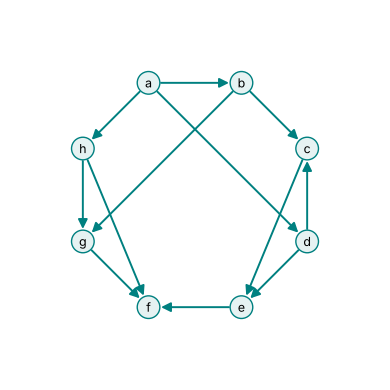

{'a': (0, 3), 'b': (1, 2), 'c': (2, 1), 'd': (1, 2), 'e': (2, 1), 'f': (3, 0), 'g': (2, 1), 'h': (1, 2)}
fuentes: ['a']  pozos: ['f']  conexo: True
suma de ingrados = suma de exgrados = 12 = 12


In [4]:
V = list("abcdefgh")
A = [("a", "b"), ("a", "d"), ("a", "h"), ("b", "c"), ("b", "g"), ("d", "c"),
     ("d", "e"), ("c", "e"), ("h", "g"), ("h", "f"), ("g", "f"), ("e", "f")]
import math
octo = {v: (math.cos(math.radians(a)), math.sin(math.radians(a)))
        for v, a in zip("abcdefgh", [112.5, 67.5, 22.5, -22.5, -67.5, -112.5, -157.5, 157.5])}
dibujar(octo, A, dirigido=True, tam=(4, 4))
print(tabla_grados(V, A))
print("fuentes:", fuentes(V, A), " pozos:", pozos(V, A), " conexo:", es_conexo(V, A))
print("suma de ingrados = suma de exgrados =", sum(ingrado(x, A) for x in V), "=", len(A))

## 2. Matriz, trayectorias y aciclicidad

$m^{(k)}_{ij}$ es el número de trayectorias de longitud $k$ de $x_i$ a $x_j$. El dígrafo es acíclico si y sólo si la diagonal de todas las potencias es nula (basta $k\le n$).

La relación del ejemplo de la sesión 10: $\mathcal R=\{(a,c),(a,d),(b,a),(b,b),(c,a),(c,b),(d,b)\}$.

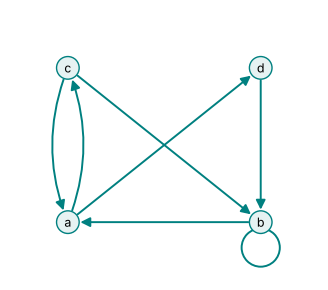

M^1 = [[0, 0, 1, 1], [1, 1, 0, 0], [1, 1, 0, 0], [0, 1, 0, 0]]   diagonal: [0, 1, 0, 0]
M^2 = [[1, 2, 0, 0], [1, 1, 1, 1], [1, 1, 1, 1], [1, 1, 0, 0]]   diagonal: [1, 1, 1, 0]
M^3 = [[2, 2, 1, 1], [2, 3, 1, 1], [2, 3, 1, 1], [1, 1, 1, 1]]   diagonal: [2, 3, 1, 1]


In [5]:
def producto(P, Q):
    Qt = list(zip(*Q))
    return [[sum(a * b for a, b in zip(f, col)) for col in Qt] for f in P]

Vr = list("abcd")
R = [("a", "c"), ("a", "d"), ("b", "a"), ("b", "b"), ("c", "a"), ("c", "b"), ("d", "b")]
dibujar({"a": (0, 0), "b": (2, 0), "c": (0, 1.6), "d": (2, 1.6)}, R, dirigido=True)
M = matriz(Vr, R)
M2 = producto(M, M)
M3 = producto(M2, M)
for k, P in ((1, M), (2, M2), (3, M3)):
    print(f"M^{k} =", P, "  diagonal:", [P[i][i] for i in range(4)])

La diagonal no es nula: hay ciclos (el lazo en $b$, el ciclo $a\to c\to a$...).

## 3. Warshall y el cierre transitivo

**Con pesos.** Si cada arco pesa $1$, $w^*_{ij}$ es la longitud de la trayectoria más corta de $x_i$ a $x_j$, y $w^*_{ij}\ne\infty$ si y sólo si $t_{ij}=1$ en el cierre transitivo.

In [6]:
INF = float("inf")


def warshall(W, traza=False):
    """
    W^(k) contiene los pesos mínimos de los caminos cuyos vértices intermedios
    están en {1, ..., k}:
        w_ij^(k) = min( w_ij^(k-1), w_ik^(k-1) + w_kj^(k-1) ).
    Devuelve (W*, siguiente); siguiente[i][j] es el vértice que sigue a i en un
    camino mínimo de i a j. Con traza=True devuelve también la lista de las W^(k).
    """
    n = len(W)
    A = [fila[:] for fila in W]
    sig = [[(j if W[i][j] < INF else None) for j in range(n)] for i in range(n)]
    pasos = [[fila[:] for fila in A]]
    for k in range(n):
        for i in range(n):
            for j in range(n):
                if A[i][k] + A[k][j] < A[i][j]:
                    A[i][j] = A[i][k] + A[k][j]
                    sig[i][j] = sig[i][k]
        pasos.append([fila[:] for fila in A])
    return (A, sig, pasos) if traza else (A, sig)


def mostrar_pesos(W, etiquetas=None, ancho=3):
    n = len(W)
    etiquetas = etiquetas or [str(i + 1) for i in range(n)]
    print(" " * ancho + "".join(e.rjust(ancho) for e in etiquetas))
    for e, fila in zip(etiquetas, W):
        print(e.rjust(ancho) + "".join(fmt_peso(w).rjust(ancho) for w in fila))


def fmt_peso(w):
    return "∞" if w == INF else str(int(w) if w == int(w) else w)

In [7]:
M1 = [[0, 1, 1, 0], [0, 0, 0, 1], [0, 1, 0, 1], [0, 0, 1, 0]]   # R = {(1,2),(1,3),(2,4),(3,2),(3,4),(4,3)}
W1 = [[1 if x else INF for x in fila] for fila in M1]
Ws, _ = warshall(W1)
mostrar_pesos(Ws)
print("T =", [[int(w < INF) for w in fila] for fila in Ws])

     1  2  3  4
  1  ∞  1  1  2
  2  ∞  3  2  1
  3  ∞  1  2  1
  4  ∞  2  1  2
T = [[0, 1, 1, 1], [0, 1, 1, 1], [0, 1, 1, 1], [0, 1, 1, 1]]


**Con ceros y unos.** Si sólo interesa si hay trayectoria: $t_{ij}\leftarrow t_{ij}\lor(t_{ik}\land t_{kj})$.

In [8]:
def warshall_booleano(M, traza=False):
    """
    T^(k)_ij = 1 si hay un camino de i a j con vértices intermedios en
    {1, ..., k}. Paso k: t_ij = t_ij OR (t_ik AND t_kj).
    Al final, T = T^(n) es la matriz del cierre transitivo. Unas n^3 operaciones.
    """
    n = len(M)
    T = [[1 if x else 0 for x in fila] for fila in M]
    pasos = [[fila[:] for fila in T]]
    for k in range(n):
        for i in range(n):
            if T[i][k]:                      # si i llega a k...
                for j in range(n):
                    if T[k][j]:              # ...y k llega a j, entonces i llega a j
                        T[i][j] = 1
        pasos.append([fila[:] for fila in T])
    return (T, pasos) if traza else T


def es_aciclico(vertices, arcos):
    """Acíclico si ningún vértice llega a sí mismo: diagonal nula en t(M)."""
    T = warshall_booleano(matriz(vertices, arcos))
    return all(T[i][i] == 0 for i in range(len(vertices)))

In [9]:
M13 = [[0, 0, 1, 1], [0, 1, 0, 0], [0, 0, 1, 0], [1, 0, 0, 0]]     # la relación de la sesión 13
T, pasos = warshall_booleano(M13, traza=True)
for k, P in enumerate(pasos):
    print(f"T({k}) =", P)
print(es_aciclico(V, A), es_aciclico(Vr, R))

T(0) = [[0, 0, 1, 1], [0, 1, 0, 0], [0, 0, 1, 0], [1, 0, 0, 0]]
T(1) = [[0, 0, 1, 1], [0, 1, 0, 0], [0, 0, 1, 0], [1, 0, 1, 1]]
T(2) = [[0, 0, 1, 1], [0, 1, 0, 0], [0, 0, 1, 0], [1, 0, 1, 1]]
T(3) = [[0, 0, 1, 1], [0, 1, 0, 0], [0, 0, 1, 0], [1, 0, 1, 1]]
T(4) = [[1, 0, 1, 1], [0, 1, 0, 0], [0, 0, 1, 0], [1, 0, 1, 1]]
True False


### Comparación con la sesión 13

En la sesión 13 calculamos el cierre transitivo sumando las potencias $M+M^2+\dots+M^n$ (unas $n^4$ operaciones) y resolviendo un sistema lineal con fracciones. Copiamos aquí aquellas funciones para compararlas con Warshall.

In [10]:
from fractions import Fraction


def identidad(n):
    return [[1 if i == j else 0 for j in range(n)] for i in range(n)]


def traspuesta(M):
    return [list(fila) for fila in zip(*M)]


def suma_bool(M, N):
    """(M + N)_ij = M_ij OR N_ij"""
    return [[a | b for a, b in zip(f, g)] for f, g in zip(M, N)]


def producto_bool(M, N):
    """(M N)_ij = OR_k (M_ik AND N_kj)"""
    Nt = traspuesta(N)
    return [[int(any(a & b for a, b in zip(f, c))) for c in Nt] for f in M]


def cierre_transitivo(M):
    T = P = M
    for _ in range(len(M) - 1):
        P = producto_bool(P, M)                     # P = M^k
        T = suma_bool(T, P)                         # T = M + ... + M^k
    return T


def resolver(A, B):
    """Solución exacta (en Q) de A X = B, con A invertible (Gauss-Jordan)."""
    n = len(A)
    F = [[Fraction(x) for x in A[i] + B[i]] for i in range(n)]
    for c in range(n):
        p = next(i for i in range(c, n) if F[i][c] != 0)    # pivote
        F[c], F[p] = F[p], F[c]
        piv = F[c][c]
        F[c] = [x / piv for x in F[c]]
        for i in range(n):
            if i != c and F[i][c] != 0:
                f = F[i][c]
                F[i] = [x - f * y for x, y in zip(F[i], F[c])]
    return [fila[n:] for fila in F]


def cierre_transitivo_limite(M):
    """
    Con k -> infinito y M/(n+1) en lugar de M: ((n+1) I - M) Y = I.
    Entonces M Y = (n+1) Y - I tiene las mismas entradas no nulas que t(M).
    """
    n = len(M)
    A = [[(n + 1) * (i == j) - M[i][j] for j in range(n)]
         for i in range(n)]                                    # (n+1) I - M
    Y = resolver(A, identidad(n))
    Z = [[(n + 1) * Y[i][j] - (i == j) for j in range(n)]
         for i in range(n)]                                    # Z = M Y
    return [[int(z != 0) for z in fila] for fila in Z]

In [11]:
random.seed(2026)
for n in (20, 40, 80, 160):
    Q = [[int(random.random() < 1.5 / n) for _ in range(n)] for _ in range(n)]
    t0 = time.perf_counter(); T1 = cierre_transitivo(Q)
    t1 = time.perf_counter(); T2 = cierre_transitivo_limite(Q)
    t2 = time.perf_counter(); T3 = warshall_booleano(Q)
    t3 = time.perf_counter()
    assert T1 == T2 == T3
    print(f"n = {n:>3}: potencias {t1 - t0:6.2f} s | límite {t2 - t1:5.2f} s | Warshall {t3 - t2:6.3f} s")

n =  20: potencias   0.01 s | límite  0.00 s | Warshall  0.000 s


n =  40: potencias   0.16 s | límite  0.03 s | Warshall  0.001 s


n =  80: potencias   2.05 s | límite  0.11 s | Warshall  0.006 s


n = 160: potencias  21.63 s | límite  1.20 s | Warshall  0.058 s


Warshall gana con claridad: unas $n^3$ operaciones con ceros y unos, y además la línea `if T[i][k]` se salta filas enteras cuando la relación es dispersa.

## 4. Isomorfismo de dígrafos

Un isomorfismo conserva los arcos con su sentido. Invariantes: $|V|$, $|A|$, la familia de pares $(ing,exg)$, el grafo subyacente, los ciclos...

In [12]:
def isomorfismo(V1, A1, V2, A2):
    """Biyección psi: V1 -> V2 con (x, y) arco de D1 <=> (psi(x), psi(y)) arco de D2."""
    if len(V1) != len(V2) or len(A1) != len(A2):
        return None
    g1, g2 = tabla_grados(V1, A1), tabla_grados(V2, A2)
    if sorted(g1.values()) != sorted(g2.values()):
        return None
    B = set(A2)
    for imagen in permutations(V2):
        psi = dict(zip(V1, imagen))
        if all(g1[x] == g2[psi[x]] for x in V1) and all((psi[a], psi[b]) in B for a, b in A1):
            return psi
    return None


def digrafos_simples(vertices, m=None):
    """Todos los dígrafos simples (sin lazos) con esos vértices (y m arcos)."""
    posibles = [(x, y) for x in vertices for y in vertices if x != y]
    for bits in product((0, 1), repeat=len(posibles)):
        arcos = [a for a, b in zip(posibles, bits) if b]
        if m is None or len(arcos) == m:
            yield arcos


def forma_canonica(vertices, arcos):
    n = len(vertices)
    mejor = None
    for perm in permutations(range(n)):
        psi = dict(zip(vertices, perm))
        forma = tuple(sorted((psi[a], psi[b]) for a, b in arcos))
        if mejor is None or forma < mejor:
            mejor = forma
    return mejor


def clases_de_isomorfia(vertices, digrafos):
    clases = {}
    for A in digrafos:
        clases.setdefault(forma_canonica(vertices, A), []).append(A)
    return list(clases.values())

In [13]:
V3 = ["x", "y", "z"]
print(len(list(digrafos_simples(V3))), "dígrafos simples etiquetados,",
      len(clases_de_isomorfia(V3, digrafos_simples(V3))), "no etiquetados")
for m in range(7):
    C = clases_de_isomorfia(V3, digrafos_simples(V3, m))
    print(f"  {m} arcos: {len(C)} no etiquetados, tamaños {[len(cl) for cl in C]}")

64 dígrafos simples etiquetados, 16 no etiquetados
  0 arcos: 1 no etiquetados, tamaños [1]
  1 arcos: 1 no etiquetados, tamaños [6]
  2 arcos: 4 no etiquetados, tamaños [3, 3, 6, 3]
  3 arcos: 4 no etiquetados, tamaños [6, 6, 6, 2]
  4 arcos: 4 no etiquetados, tamaños [3, 3, 6, 3]
  5 arcos: 1 no etiquetados, tamaños [6]
  6 arcos: 1 no etiquetados, tamaños [1]


Un representante de cada clase con $2$ arcos (problema 4.18 b):

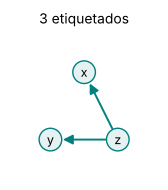

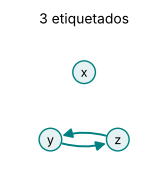

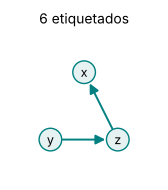

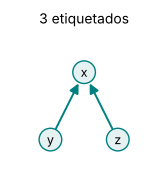

In [14]:
tri = {"x": (0.5, 1), "y": (0, 0), "z": (1, 0)}
for cl in clases_de_isomorfia(V3, digrafos_simples(V3, 2)):
    dibujar(tri, cl[0], dirigido=True, titulo=f"{len(cl)} etiquetados", tam=(2, 2))

## 5. Dígrafos y relaciones

Un dígrafo simple simétrico y transitivo corresponde a una relación de equivalencia (sin los lazos): sus componentes conexas son las clases. Uno antisimétrico y transitivo corresponde a un orden.

In [15]:
def propiedades(vertices, arcos):
    A_ = set(arcos)
    return {"simétrico": all((y, x) in A_ for x, y in A_),
            "antisimétrico": all((y, x) not in A_ for x, y in A_),
            "transitivo": all((x, z) in A_ for x, y in A_ for y2, z in A_ if y == y2 and x != z)}

# congruencia módulo 3 en {1,...,6}, sin lazos
E = list(range(1, 7))
cong = [(a, b) for a in E for b in E if a != b and (a - b) % 3 == 0]
print(propiedades(E, cong))
# "divide a" en {1,...,6}, sin lazos
div = [(a, b) for a in E for b in E if a != b and b % a == 0]
print(propiedades(E, div))

{'simétrico': True, 'antisimétrico': False, 'transitivo': True}
{'simétrico': False, 'antisimétrico': True, 'transitivo': True}


## 6. Dígrafos acíclicos

Todo dígrafo acíclico finito tiene maximales y minimales. Un etiquetado $x_1,\dots,x_n$ es **naturalmente ordenado** si todos los arcos van de índice menor a mayor. Se obtiene tomando un maximal como $x_n$, quitándolo, y repitiendo: es la clasificación topológica de la sesión 11, empezando por arriba.

In [16]:
def maximales(restantes, arcos):
    """Vértices de los que no sale ningún arco hacia los restantes."""
    r = set(restantes)
    return [x for x in restantes if not any(a == x and b in r for a, b in arcos)]


def minimales(restantes, arcos):
    r = set(restantes)
    return [x for x in restantes if not any(b == x and a in r for a, b in arcos)]


def etiquetado_natural(vertices, arcos, eleccion=None, traza=False):
    """
    Etiquetado naturalmente ordenado: se toma un maximal, se le da la etiqueta
    más alta que quede (x_n, x_{n-1}, ...) y se elimina. Si en algún paso no
    hay maximales, el dígrafo tiene un ciclo.
    Devuelve {vértice: etiqueta}.
    """
    eleccion = eleccion or (lambda c: c[0])
    restantes = list(vertices)
    etiqueta = {}
    for k in range(len(vertices), 0, -1):
        maxs = maximales(restantes, arcos)
        if not maxs:
            raise ValueError("Hay un ciclo: el dígrafo no es acíclico")
        x = eleccion(maxs)
        etiqueta[x] = k
        restantes.remove(x)
        if traza:
            print(f"  maximales {fmt(maxs):<14} -> x{k} = {x}")
    return etiqueta


def es_naturalmente_ordenado(etiqueta, arcos):
    """Todos los arcos van de etiqueta menor a etiqueta mayor."""
    return all(etiqueta[a] < etiqueta[b] for a, b in arcos)


def fmt(conjunto):
    return "{" + ", ".join(map(str, conjunto)) + "}"

In [17]:
et = etiquetado_natural(V, A, traza=True)
print(et, es_naturalmente_ordenado(et, A))
clase = {"a": 1, "d": 2, "b": 3, "c": 4, "h": 5, "e": 6, "g": 7, "f": 8}    # el de las transparencias
print(es_naturalmente_ordenado(clase, A))

  maximales {f}            -> x8 = f
  maximales {e, g}         -> x7 = e
  maximales {c, g}         -> x6 = c
  maximales {d, g}         -> x5 = d
  maximales {g}            -> x4 = g
  maximales {b, h}         -> x3 = b
  maximales {h}            -> x2 = h
  maximales {a}            -> x1 = a
{'f': 8, 'e': 7, 'c': 6, 'd': 5, 'g': 4, 'b': 3, 'h': 2, 'a': 1} True
True


Con otro criterio de elección sale otro etiquetado. Por ejemplo, eligiendo siempre el último maximal en orden alfabético:

In [18]:
print(etiquetado_natural(V, A, eleccion=max, traza=True))

  maximales {f}            -> x8 = f
  maximales {e, g}         -> x7 = g
  maximales {e, h}         -> x6 = h
  maximales {e}            -> x5 = e
  maximales {c}            -> x4 = c
  maximales {b, d}         -> x3 = d
  maximales {b}            -> x2 = b
  maximales {a}            -> x1 = a
{'f': 8, 'g': 7, 'h': 6, 'e': 5, 'c': 4, 'd': 3, 'b': 2, 'a': 1}


Si hay un ciclo, en algún paso no quedan maximales:

In [19]:
try:
    etiquetado_natural(Vr, R)
except ValueError as e:
    print(e)

Hay un ciclo: el dígrafo no es acíclico


### Niveles

$N_0$ son los minimales, $N_1$ los minimales de lo que queda, etc. Un etiquetado es **naturalmente ordenado por niveles** si además los vértices de niveles inferiores tienen índices menores.

In [20]:
def niveles(vertices, arcos):
    """N_0 = minimales, N_1 = minimales de lo que queda, ..."""
    restantes = list(vertices)
    resultado = []
    while restantes:
        mins = minimales(restantes, arcos)
        if not mins:
            raise ValueError("Hay un ciclo: el dígrafo no es acíclico")
        resultado.append(mins)
        restantes = [x for x in restantes if x not in mins]
    return resultado


def etiquetado_por_niveles(vertices, arcos):
    """Se numeran los vértices nivel a nivel: es naturalmente ordenado por niveles."""
    etiqueta, k = {}, 1
    for N in niveles(vertices, arcos):
        for x in N:
            etiqueta[x] = k
            k += 1
    return etiqueta


def es_por_niveles(etiqueta, vertices, arcos):
    """Naturalmente ordenado y respeta los niveles: nivel menor => etiqueta menor."""
    nivel = {x: p for p, N in enumerate(niveles(vertices, arcos)) for x in N}
    ok_niveles = all(etiqueta[x] < etiqueta[y] for x in vertices for y in vertices
                     if nivel[x] < nivel[y])
    return es_naturalmente_ordenado(etiqueta, arcos) and ok_niveles

niveles: [['a'], ['b', 'd', 'h'], ['c', 'g'], ['e'], ['f']]
por niveles: {'a': 1, 'b': 2, 'd': 3, 'h': 4, 'c': 5, 'g': 6, 'e': 7, 'f': 8} True
el de las transparencias, ¿por niveles? False


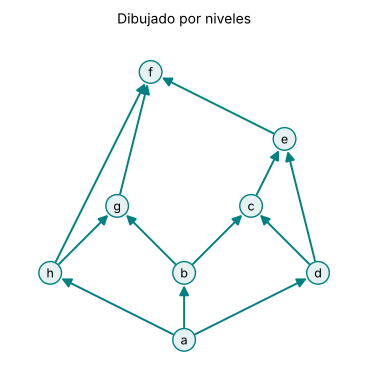

In [21]:
N = niveles(V, A)
print("niveles:", N)
ep = etiquetado_por_niveles(V, A)
print("por niveles:", ep, es_por_niveles(ep, V, A))
print("el de las transparencias, ¿por niveles?", es_por_niveles(clase, V, A))
pos_niv = {"a": (2, 0), "h": (0, 1), "b": (2, 1), "d": (4, 1), "g": (1, 2), "c": (3, 2), "e": (3.5, 3), "f": (1.5, 4)}
dibujar(pos_niv, A, dirigido=True, titulo="Dibujado por niveles", tam=(4, 4));

$h=x_5$ está en $N_1$ y $c=x_4$ en $N_2$: el etiquetado de las transparencias es naturalmente ordenado, pero no por niveles.

## Referencias

- Warshall, S. (1962). A theorem on Boolean matrices. *Journal of the ACM*, 9(1), 11–12.
- Grimaldi, R. P. (1998). *Matemática discreta y combinatoria* (3ª ed.). Addison Wesley Longman. Capítulo 11.
- Rosen, K. H. (2004). *Matemática discreta y sus aplicaciones* (5ª ed.). McGraw-Hill. Capítulo 8.